# Correlación de Pearson, Spearman y Kendall en datos transaccionales

**Objetivo.** Identificar relaciones entre variables de un conjunto de datos transaccional *simulado* y decidir, con evidencia, qué coeficiente de correlación describe mejor los datos: **Pearson** (lineal, paramétrico), **Spearman** (monótono, basado en rangos) o **Kendall** (concordancia de pares, basado en rangos).

**Contenido**

1. Preparación del entorno y generación del dataset
2. Análisis de supuestos (¿hay normalidad? ¿hay valores atípicos?)
3. Cálculo de los tres coeficientes: matrices, pares clave y sensibilidad a atípicos / no linealidad
4. Correlación no implica causalidad (confusores en el negocio)
5. Conclusiones: ¿qué método es el más robusto para este dataset?

> **Nota de reproducibilidad.** Todo el dataset se genera con una semilla fija (`SEED = 42`), por lo que el notebook es ejecutable de principio a fin sin archivos externos. Los valores numéricos citados en los textos corresponden a esa semilla; con otras versiones de NumPy podrían variar levemente en los decimales, pero no las conclusiones.

## 1. Preparación del entorno

Se usan solo librerías estándar del ecosistema de análisis de datos: `pandas`, `numpy`, `scipy.stats` (para los coeficientes y sus *p-values*) y `matplotlib`/`seaborn` (para las visualizaciones).

In [1]:
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

SEED = 42
rng = np.random.default_rng(SEED)

# Colores consistentes para los tres métodos en todos los gráficos
COLOR = {"Pearson": "#C44E52", "Spearman": "#4C72B0", "Kendall": "#55A868"}

print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | seaborn {sns.__version__}")

Matplotlib is building the font cache; this may take a moment.


numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | seaborn 0.13.2


### 1.1 Dataset transaccional simulado

Cada fila es una **transacción de compra online** (1 500 transacciones). El dataset se diseñó para que contenga, a propósito, las situaciones que hacen que los tres coeficientes se comporten distinto:

| Característica | Variables involucradas | Qué ponemos a prueba |
|---|---|---|
| Distribuciones muy asimétricas (log-normal, gamma) | `tiempo_sesion_min`, `precio_unitario`, `monto_total`, `antiguedad_cliente_meses` | Supuesto de normalidad de Pearson |
| Valores atípicos (1 % de compras corporativas 15–40 veces mayores) | `monto_total` | Sensibilidad de Pearson a *outliers* |
| Relación monótona **no lineal** (convexa) | `antiguedad_cliente_meses` → `puntos_fidelidad` | Pearson vs. coeficientes de rangos |
| Variable **ordinal** con muchos empates | `descuento_pct`, `satisfaccion` (1–5) | Spearman vs. Kendall |
| Variable **confusora** (la antigüedad influye en compras y en tickets de soporte) | `tickets_soporte`, `monto_total` | Correlación espuria / causalidad |

In [2]:
n = 1500  # número de transacciones

# --- Perfil del cliente y de la sesión -------------------------------------------------
antiguedad_cliente_meses = rng.gamma(shape=2.0, scale=12.0, size=n).round(1)        # asimétrica a la derecha
visitas_previas = rng.poisson(2 + 0.08 * antiguedad_cliente_meses)                   # conteo
tiempo_sesion_min = rng.lognormal(mean=2.4, sigma=0.5, size=n).round(1)              # log-normal

# --- Características de la compra ------------------------------------------------------
cantidad_items = 1 + rng.poisson(0.8 + 0.05 * tiempo_sesion_min + 0.02 * antiguedad_cliente_meses)
precio_unitario = (rng.lognormal(mean=3.4, sigma=0.55, size=n)
                   * (1 + 0.006 * antiguedad_cliente_meses)).round(2)
descuento_pct = rng.choice([0, 5, 10, 15, 20, 25], size=n, p=[0.35, 0.20, 0.20, 0.12, 0.08, 0.05])

monto_total = (cantidad_items * precio_unitario * (1 - descuento_pct / 100)
               * rng.lognormal(mean=0, sigma=0.10, size=n))

# Compras corporativas atípicas: 15 transacciones (1 %) entre 15 y 40 veces mayores
idx_atipicos = rng.choice(n, size=15, replace=False)
monto_total[idx_atipicos] *= rng.uniform(15, 40, size=15)
monto_total = monto_total.round(2)

# --- Postventa -------------------------------------------------------------------------
tickets_soporte = rng.poisson(0.10 + 0.05 * antiguedad_cliente_meses)               # más antigüedad -> más tickets
latente = 3.0 + 0.04 * descuento_pct - 0.35 * tickets_soporte + rng.normal(0, 0.8, size=n)
satisfaccion = np.clip(np.round(latente), 1, 5).astype(int)                          # ordinal 1-5

# Relación monótona no lineal (convexa): los puntos se aceleran con la antigüedad
puntos_fidelidad = (4 * antiguedad_cliente_meses ** 1.5 * rng.lognormal(0, 0.15, size=n)).round(0)

df = pd.DataFrame({
    "antiguedad_cliente_meses": antiguedad_cliente_meses,
    "visitas_previas": visitas_previas,
    "tiempo_sesion_min": tiempo_sesion_min,
    "cantidad_items": cantidad_items,
    "precio_unitario": precio_unitario,
    "descuento_pct": descuento_pct,
    "monto_total": monto_total,
    "tickets_soporte": tickets_soporte,
    "satisfaccion": satisfaccion,
    "puntos_fidelidad": puntos_fidelidad,
})
df.index.name = "id_transaccion"

print(f"Dimensiones: {df.shape[0]} transacciones x {df.shape[1]} variables | valores nulos: {int(df.isna().sum().sum())}")
df.head()

Dimensiones: 1500 transacciones x 10 variables | valores nulos: 0


,antiguedad_cliente_meses,visitas_previas,tiempo_sesion_min,cantidad_items,precio_unitario,descuento_pct,monto_total,tickets_soporte,satisfaccion,puntos_fidelidad
id_transaccion,,,,,,,,,,
0,25.1,6,8.6,1,47.44,0,41.54,1,3,505.0
1,34.0,5,33.9,3,28.38,5,73.60,1,1,739.0
2,22.0,4,13.6,2,33.85,15,65.19,1,3,383.0
3,19.7,2,6.7,2,37.25,5,80.45,1,4,368.0
4,37.0,3,9.2,2,20.56,20,32.65,0,4,879.0


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
antiguedad_cliente_meses,1500.0,24.296,17.478,0.40,11.775,20.700,32.400,120.70
visitas_previas,1500.0,3.889,2.437,0.00,2.000,4.000,5.000,23.00
tiempo_sesion_min,1500.0,12.475,6.845,2.30,7.900,10.900,15.500,87.80
cantidad_items,1500.0,2.921,1.458,1.00,2.000,3.000,4.000,10.00
precio_unitario,1500.0,41.118,24.477,5.32,24.565,34.685,52.392,203.87
descuento_pct,1500.0,7.617,7.405,0.00,0.000,5.000,10.000,25.00
monto_total,1500.0,130.666,224.072,6.00,48.843,88.170,150.968,5264.58
tickets_soporte,1500.0,1.302,1.451,0.00,0.000,1.000,2.000,10.00
satisfaccion,1500.0,2.876,0.978,1.00,2.000,3.000,4.000,5.00
puntos_fidelidad,1500.0,580.435,656.943,1.00,155.750,371.000,754.250,6209.00


## 2. Análisis de supuestos: normalidad, forma y atípicos

Pearson describe la asociación lineal y puede calcularse aunque las variables sean asimétricas. Su prueba paramétrica habitual sí depende de supuestos de distribución e independencia. Revisamos histogramas, gráficos Q-Q y tests de normalidad marginal (Shapiro-Wilk y D'Agostino-Pearson). Los gráficos de dispersión de la sección 3 permiten evaluar la forma de cada relación.

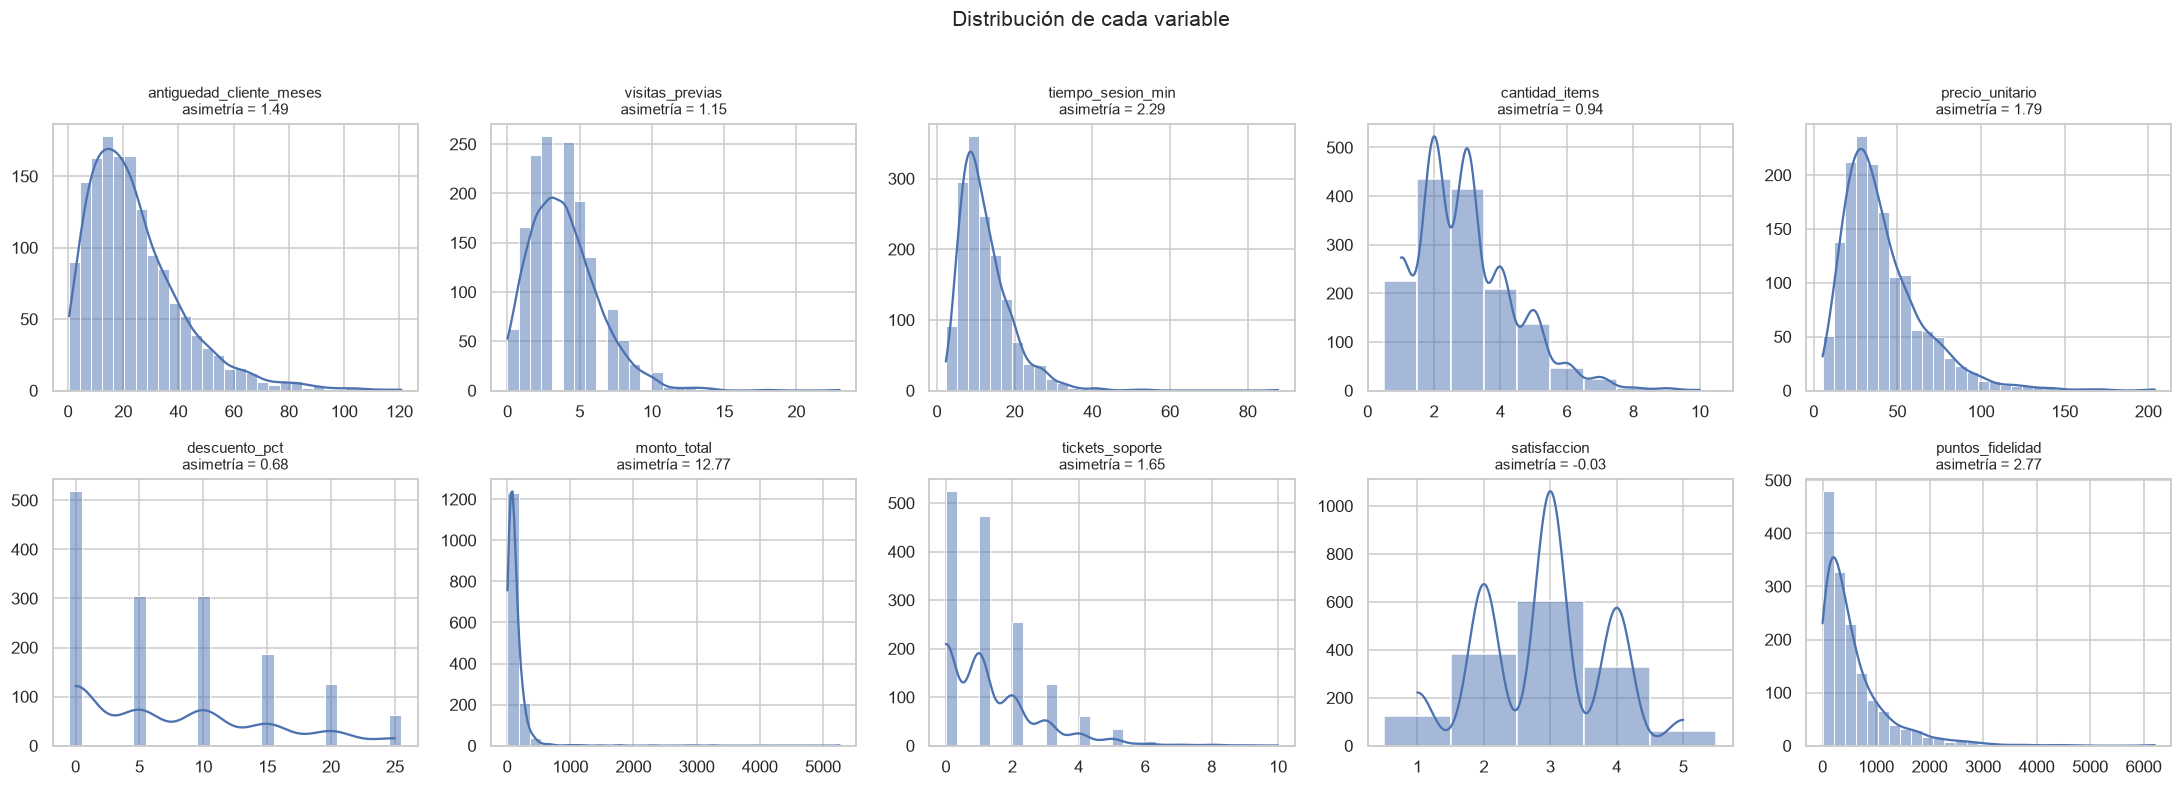

In [4]:
# Histogramas con densidad (KDE) de las 10 variables
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), df.columns):
    es_discreta = df[col].nunique() <= 10
    sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0", discrete=es_discreta, **({} if es_discreta else {"bins": 30}))
    ax.set_title(f"{col}\nasimetría = {stats.skew(df[col]):.2f}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Distribución de cada variable", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

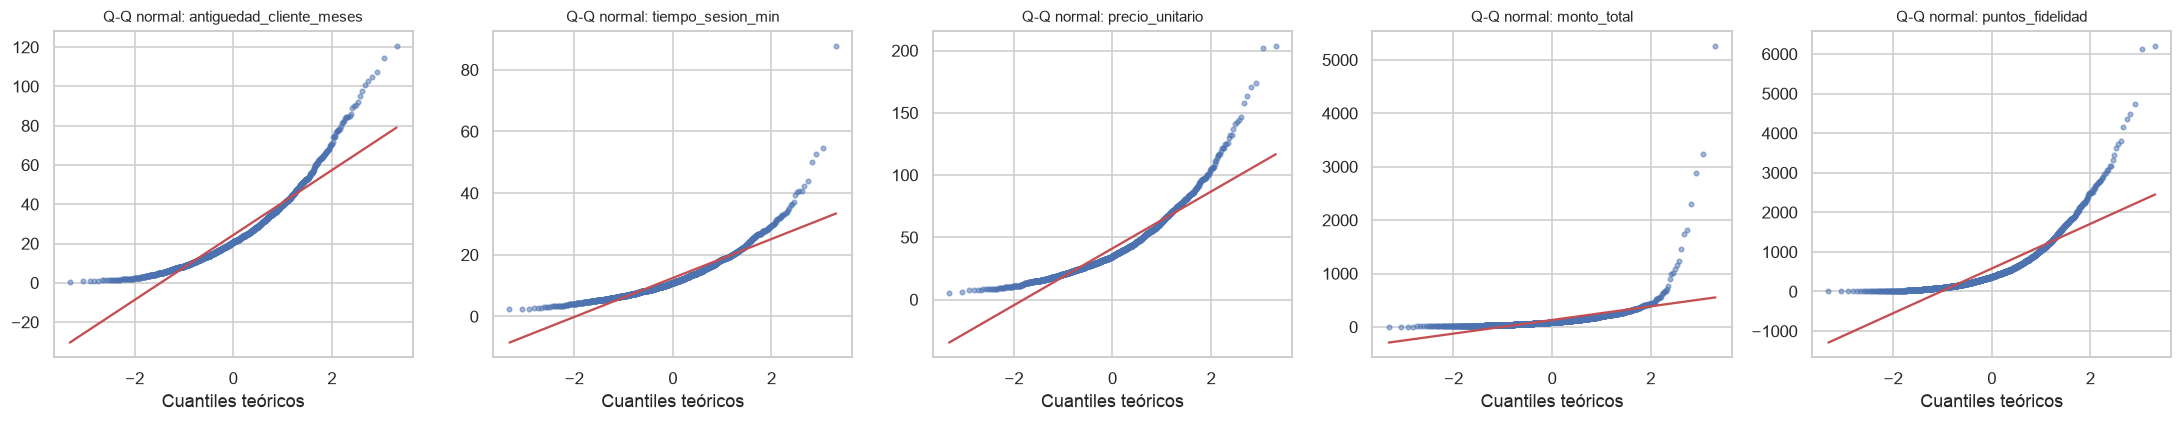

In [5]:
# Gráficos Q-Q contra la normal: si los puntos siguen la recta roja, la variable es ~normal
cols_qq = ["antiguedad_cliente_meses", "tiempo_sesion_min", "precio_unitario", "monto_total", "puntos_fidelidad"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, cols_qq):
    stats.probplot(df[col], dist="norm", plot=ax)
    ax.get_lines()[0].set(markersize=3, alpha=0.5, color="#4C72B0")
    ax.get_lines()[1].set(color="#C44E52")
    ax.set_title(f"Q-Q normal: {col}", fontsize=10)
    ax.set_xlabel("Cuantiles teóricos")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [6]:
# Tests formales de normalidad (H0: la variable proviene de una distribución normal)
filas = []
for col in df.columns:
    x = df[col].to_numpy(dtype=float)
    w, p_sw = stats.shapiro(x)
    _, p_dp = stats.normaltest(x)
    filas.append({
        "variable": col,
        "asimetría": stats.skew(x),
        "curtosis (exceso)": stats.kurtosis(x),
        "Shapiro W": w,
        "p Shapiro": p_sw,
        "p D'Agostino": p_dp,
        "Decisión (α=0,05)": "No se rechaza" if (p_sw >= 0.05 and p_dp >= 0.05) else "Se rechaza",
    })
tabla_normalidad = pd.DataFrame(filas).set_index("variable")
tabla_normalidad.style.format({"p Shapiro": "{:.2e}", "p D'Agostino": "{:.2e}"})

,asimetría,curtosis (exceso),Shapiro W,p Shapiro,p D'Agostino,"Decisión (α=0,05)"
variable,,,,,,
antiguedad_cliente_meses,1.492102,3.158741,0.890380,2.32e-31,2.55e-94,Se rechaza
visitas_previas,1.154137,3.704467,0.927934,3.00e-26,4.12e-78,Se rechaza
tiempo_sesion_min,2.285291,12.912938,0.851568,2.35e-35,9.31e-182,Se rechaza
cantidad_items,0.938850,1.140229,0.902692,7.34e-30,3.73e-44,Se rechaza
precio_unitario,1.785966,5.296676,0.867702,8.26e-34,3.05e-125,Se rechaza
descuento_pct,0.678568,-0.555573,0.865942,5.51e-34,7.35e-30,Se rechaza
monto_total,12.770792,233.309805,0.327491,5.24e-59,0.00e+00,Se rechaza
tickets_soporte,1.652633,3.838904,0.805416,3.92e-39,1.37e-108,Se rechaza
satisfaccion,-0.028033,-0.414028,0.906351,2.19e-29,2.13e-04,Se rechaza


In [7]:
# Valores atípicos con la regla de Tukey: 1,5·IQR (atípico) y 3·IQR (extremo)
def contar_atipicos(s, k):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - k * iqr) | (s > q3 + k * iqr)).sum())

resumen_atipicos = pd.DataFrame({
    "atípicos (1,5·IQR)": df.apply(contar_atipicos, k=1.5),
    "extremos (3·IQR)": df.apply(contar_atipicos, k=3.0),
})
resumen_atipicos["% extremos"] = (100 * resumen_atipicos["extremos (3·IQR)"] / len(df)).round(2)
display(resumen_atipicos)

m = df["monto_total"]
print(f"monto_total -> mediana: {m.median():,.1f} | percentil 99: {m.quantile(0.99):,.1f} | máximo: {m.max():,.1f} "
      f"| máximo / mediana = {m.max() / m.median():.0f}x")

,"atípicos (1,5·IQR)",extremos (3·IQR),% extremos
antiguedad_cliente_meses,56,8,0.53
visitas_previas,35,2,0.13
tiempo_sesion_min,55,10,0.67
cantidad_items,10,0,0.00
precio_unitario,57,11,0.73
descuento_pct,0,0,0.00
monto_total,85,28,1.87
tickets_soporte,23,3,0.20
satisfaccion,0,0,0.00
puntos_fidelidad,105,30,2.00


monto_total -> mediana: 88.2 | percentil 99: 677.6 | máximo: 5,264.6 | máximo / mediana = 60x


### 2.1 Decisión sobre los supuestos

**Ambos tests rechazan la normalidad marginal en las 10 variables** (Shapiro-Wilk y D'Agostino rechazan $H_0$ en todos los casos, $p < 0{,}05$), y la evidencia visual coincide con los tests: los histogramas muestran colas largas a la derecha y los Q-Q plots se separan de la recta en los extremos. Como con $n = 1\,500$ los tests de normalidad rechazan hasta desviaciones pequeñas, no nos apoyamos solo en ellos: las magnitudes de asimetría confirman que en varias variables el problema es grande, no cosmético.

- **`monto_total`** es el caso extremo: asimetría ≈ 12,8, curtosis en exceso ≈ 233, y un máximo ≈ 60 veces la mediana. Hay 28 transacciones sobre el límite $3 \cdot IQR$ (≈ 1,9 %), de las cuales 14 son compras corporativas de las 15 inyectadas (la restante quedó por debajo del límite porque partía de un monto pequeño); el resto son valores altos naturales de una distribución sesgada.
- **`tiempo_sesion_min`, `precio_unitario` y `puntos_fidelidad`** también tienen asimetría marcada (entre 1,8 y 2,8).
- **`satisfaccion`, `descuento_pct`, `tickets_soporte` y `cantidad_items`** son discretas u ordinales, con muchos empates: tampoco encajan con el modelo continuo y normal que supone Pearson.

**Decisión:** Pearson **no es apropiado como medida principal** para este dataset (distribuciones sesgadas + atípicos influyentes + variables ordinales). Usaremos **Spearman como coeficiente de referencia y Kendall como contraste** (ambos basados en rangos, sin supuesto de normalidad), y mantendremos Pearson como referencia para comparar la asociación lineal.

## 3. Cálculo y comparación de los tres coeficientes

Recordatorio de qué mide cada uno:

| Coeficiente | Qué mide | Supuestos / sensibilidad |
|---|---|---|
| **Pearson** ($r$) | Fuerza de la relación **lineal** entre los valores | Sensible a puntos influyentes. Su prueba paramétrica habitual tiene supuestos de distribución |
| **Spearman** ($\rho$) | Fuerza de la relación **monótona** (Pearson aplicado a los *rangos*) | Robusto a atípicos y a transformaciones monótonas; no exige normalidad |
| **Kendall** ($\tau_b$) | Exceso de pares **concordantes** sobre **discordantes**, normalizado teniendo en cuenta los empates | Basado en el orden y ajustado por empates; escala diferente que $\rho$ |

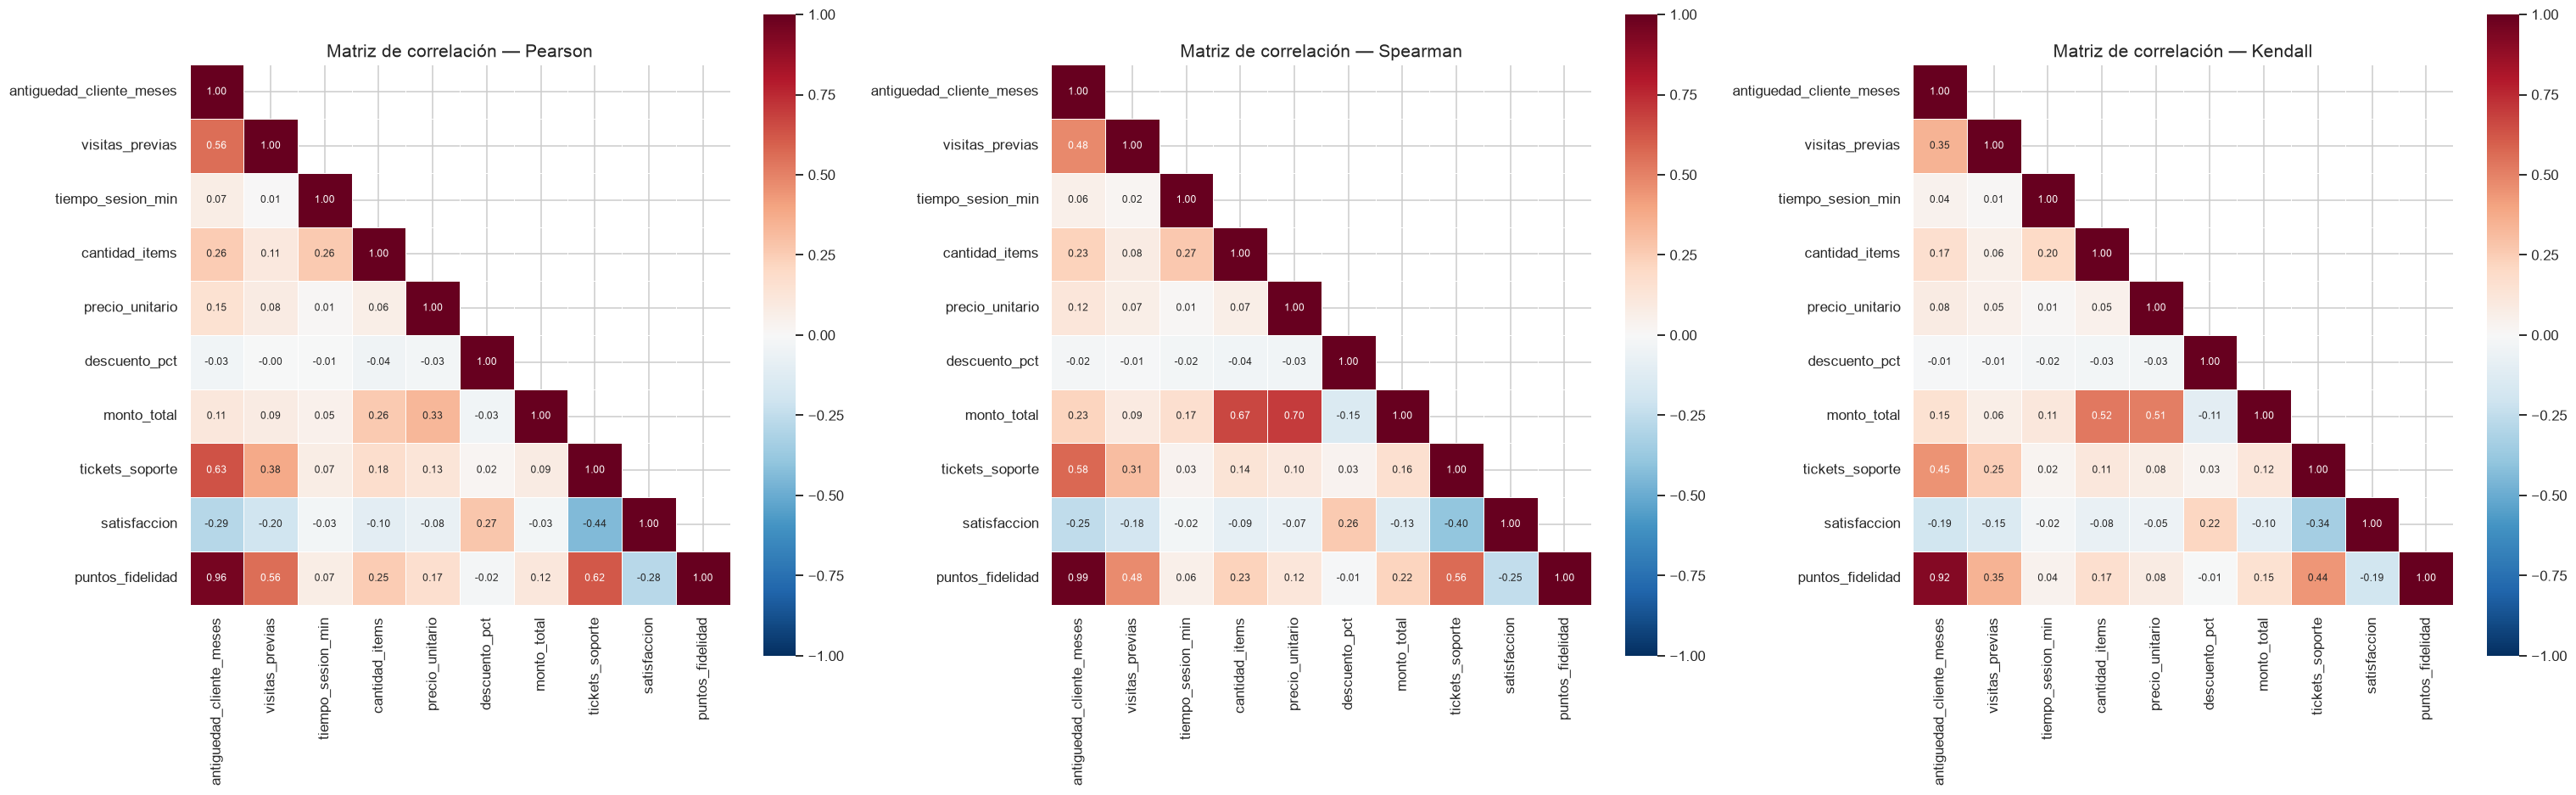

In [8]:
corr_p = df.corr(method="pearson")
corr_s = df.corr(method="spearman")
corr_k = df.corr(method="kendall")

fig, axes = plt.subplots(1, 3, figsize=(28, 8.5))
for ax, (nombre, mat) in zip(axes, [("Pearson", corr_p), ("Spearman", corr_s), ("Kendall", corr_k)]):
    mascara = np.triu(np.ones_like(mat, dtype=bool), k=1)   # solo triángulo inferior (la matriz es simétrica)
    sns.heatmap(mat, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                square=True, linewidths=0.5, cbar=True, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"Matriz de correlación — {nombre}", fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
# Los 12 pares donde más discrepan Pearson y Spearman (señal de atípicos o de no linealidad)
pares = []
cols = list(df.columns)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        pares.append({"par de variables": f"{a} — {b}",
                      "Pearson": corr_p.loc[a, b], "Spearman": corr_s.loc[a, b], "Kendall": corr_k.loc[a, b]})
comparacion = pd.DataFrame(pares).set_index("par de variables")
comparacion["|Spearman − Pearson|"] = (comparacion["Spearman"] - comparacion["Pearson"]).abs()
comparacion.sort_values("|Spearman − Pearson|", ascending=False).head(12)

,Pearson,Spearman,Kendall,|Spearman − Pearson|
par de variables,,,,
cantidad_items — monto_total,0.261,0.667,0.525,0.406
precio_unitario — monto_total,0.335,0.698,0.515,0.363
tiempo_sesion_min — monto_total,0.049,0.171,0.114,0.122
antiguedad_cliente_meses — monto_total,0.110,0.226,0.154,0.116
descuento_pct — monto_total,-0.033,-0.147,-0.108,0.113
monto_total — puntos_fidelidad,0.116,0.224,0.152,0.108
monto_total — satisfaccion,-0.028,-0.128,-0.096,0.100
visitas_previas — puntos_fidelidad,0.562,0.476,0.349,0.086
antiguedad_cliente_meses — visitas_previas,0.559,0.477,0.350,0.082


### 3.1 Los tres coeficientes, explícitamente, para pares clave (con *p-values*)

Se calculan con `scipy.stats.pearsonr`, `spearmanr` y `kendalltau` (esta última usa la variante $\tau_b$, que ajusta por empates). Elegimos seis pares que representan cada situación del dataset.

In [10]:
def tres_coeficientes(x, y):
    r, p_r = stats.pearsonr(x, y)
    rho, p_s = stats.spearmanr(x, y)
    tau, p_k = stats.kendalltau(x, y)   # tau-b (corrige empates)
    return {"Pearson r": r, "p (P)": p_r, "Spearman ρ": rho, "p (S)": p_s, "Kendall τ": tau, "p (K)": p_k}

pares_clave = [
    ("cantidad_items", "monto_total"),                 # relación fuerte con atípicos en y
    ("precio_unitario", "monto_total"),                # relación fuerte con atípicos en y
    ("antiguedad_cliente_meses", "puntos_fidelidad"),  # monótona no lineal
    ("descuento_pct", "satisfaccion"),                 # discreta / ordinal, muchos empates
    ("antiguedad_cliente_meses", "tickets_soporte"),   # conteo asimétrico
    ("tickets_soporte", "monto_total"),                # candidata a correlación espuria
]
tabla_pares = pd.DataFrame(
    [{"x": a, "y": b, **tres_coeficientes(df[a], df[b])} for a, b in pares_clave]
).set_index(["x", "y"])
tabla_pares.style.format({"p (P)": "{:.1e}", "p (S)": "{:.1e}", "p (K)": "{:.1e}"})

,,Pearson r,p (P),Spearman ρ,p (S),Kendall τ,p (K)
x,y,,,,,,
cantidad_items,monto_total,0.261350,7.6e-25,0.667060,9.6e-194,0.524663,9.0e-170
precio_unitario,monto_total,0.334879,1.2e-40,0.697564,4.0e-219,0.514901,4.1e-196
antiguedad_cliente_meses,puntos_fidelidad,0.960710,0.0e+00,0.989731,0.0e+00,0.916957,0.0e+00
descuento_pct,satisfaccion,0.274536,2.4e-27,0.259877,1.4e-24,0.215513,5.5e-24
antiguedad_cliente_meses,tickets_soporte,0.634447,9.5e-170,0.575212,7.3e-133,0.449008,1.4e-120
tickets_soporte,monto_total,0.085191,9.6e-04,0.157056,9.6e-10,0.117425,9.8e-10


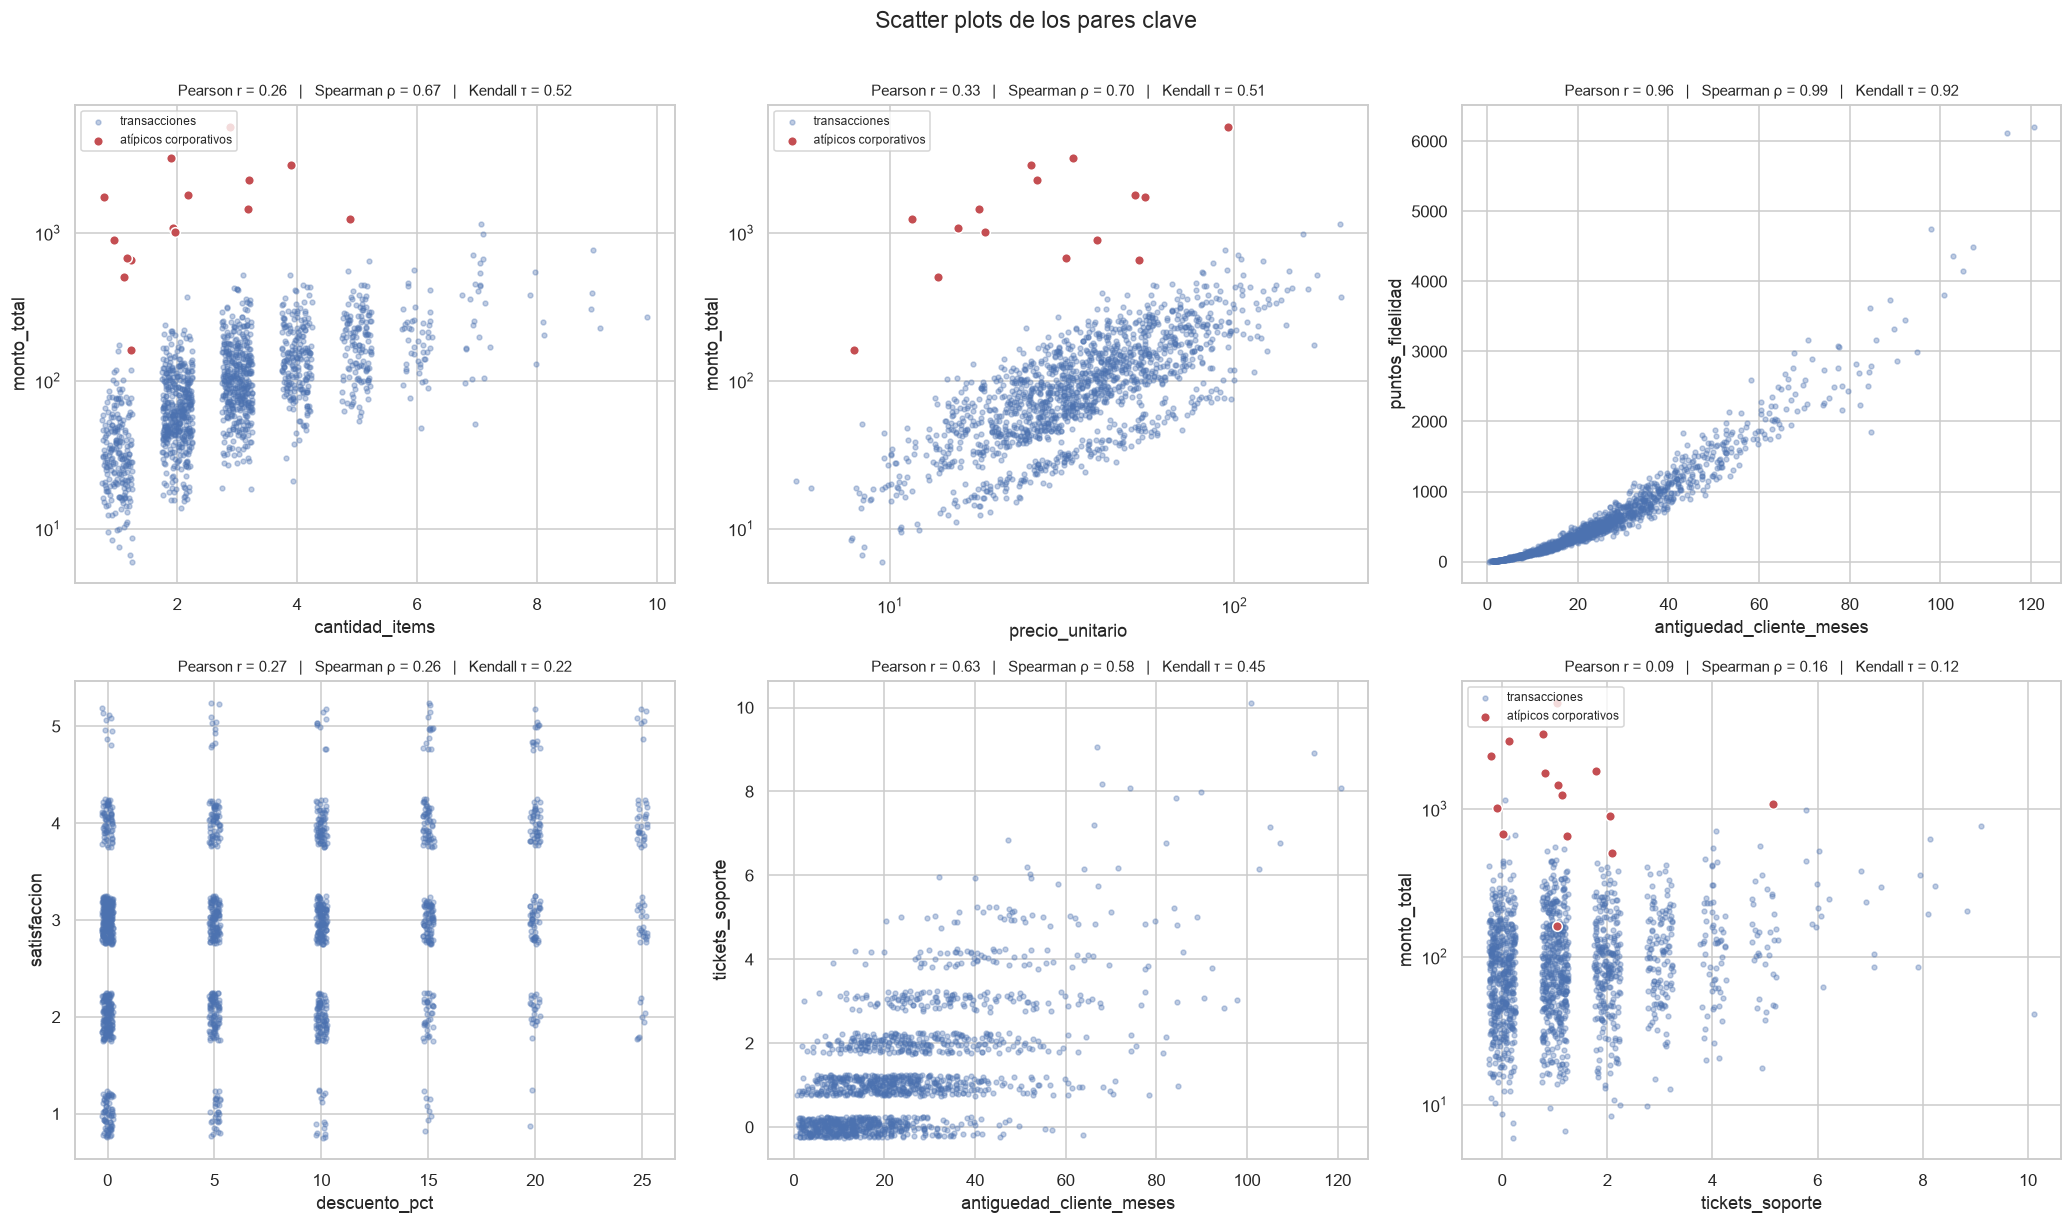

In [11]:
# Visualización de cada par: los tres coeficientes aparecen en el título del gráfico
# (rojo = las 15 compras corporativas atípicas inyectadas; eje logarítmico solo para poder verlas)
paneles = [
    ("cantidad_items", "monto_total", False, True),
    ("precio_unitario", "monto_total", True, True),
    ("antiguedad_cliente_meses", "puntos_fidelidad", False, False),
    ("descuento_pct", "satisfaccion", False, False),
    ("antiguedad_cliente_meses", "tickets_soporte", False, False),
    ("tickets_soporte", "monto_total", False, True),
]
es_atipico = df.index.isin(df.index[idx_atipicos])
rng_jit = np.random.default_rng(0)

fig, axes = plt.subplots(2, 3, figsize=(19, 11))
for ax, (a, b, logx, logy) in zip(axes.ravel(), paneles):
    c = tres_coeficientes(df[a], df[b])
    x = df[a].to_numpy(dtype=float)
    y = df[b].to_numpy(dtype=float)
    # pequeño "jitter" visual solo en variables discretas para que los empates no se tapen
    if df[a].nunique() <= 30:
        x = x + rng_jit.uniform(-0.25, 0.25, len(x))
    if df[b].nunique() <= 30:
        y = y + rng_jit.uniform(-0.25, 0.25, len(y))
    mostrar = ~es_atipico if b == "monto_total" else np.ones(len(df), dtype=bool)
    ax.scatter(x[mostrar], y[mostrar], s=10, alpha=0.35, color="#4C72B0", label="transacciones")
    if b == "monto_total":
        ax.scatter(x[es_atipico], y[es_atipico], s=40, color="#C44E52", edgecolor="white", label="atípicos corporativos")
        ax.legend(loc="upper left", fontsize=8)
    if logx:
        ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"Pearson r = {c['Pearson r']:.2f}   |   Spearman ρ = {c['Spearman ρ']:.2f}   |   Kendall τ = {c['Kendall τ']:.2f}",
                 fontsize=10)
fig.suptitle("Scatter plots de los pares clave", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

### 3.2 Efecto de los valores atípicos

Hay dos formas complementarias de verlo: (a) recalcular **con y sin** los atípicos reales del dataset, y (b) una **prueba de estrés controlada**, agregando cada vez más atípicos a datos limpios y viendo cuánto se mueve cada coeficiente.

In [12]:
# (a) Con y sin las compras extremas (regla 3·IQR sobre monto_total)
q1, q3 = df["monto_total"].quantile([0.25, 0.75])
limite_sup = q3 + 3 * (q3 - q1)
mascara_ext = df["monto_total"] > limite_sup
print(f"Transacciones extremas detectadas (monto_total > {limite_sup:,.1f}): {int(mascara_ext.sum())} de {len(df)}\n")

filas = []
for a, b in [("cantidad_items", "monto_total"), ("precio_unitario", "monto_total"), ("tiempo_sesion_min", "monto_total")]:
    con = tres_coeficientes(df[a], df[b])
    sin = tres_coeficientes(df.loc[~mascara_ext, a], df.loc[~mascara_ext, b])
    for etiqueta, clave in [("Pearson", "Pearson r"), ("Spearman", "Spearman ρ"), ("Kendall", "Kendall τ")]:
        filas.append({"par": f"{a} — {b}", "método": etiqueta, "con atípicos": con[clave],
                      "sin atípicos": sin[clave], "cambio": sin[clave] - con[clave]})
efecto_atipicos = pd.DataFrame(filas).set_index(["par", "método"])
efecto_atipicos

Transacciones extremas detectadas (monto_total > 457.3): 28 de 1500



con atípicos  sin atípicos     cambio
par                             método                                         
cantidad_items — monto_total    Pearson          0.261         0.614  3.528e-01
                                Spearman         0.667         0.681  1.423e-02
                                Kendall          0.525         0.533  8.804e-03
precio_unitario — monto_total   Pearson          0.335         0.697  3.620e-01
                                Spearman         0.698         0.709  1.097e-02
                                Kendall          0.515         0.520  5.070e-03
tiempo_sesion_min — monto_total Pearson          0.049         0.148  9.881e-02
                                Spearman         0.171         0.171 -3.059e-04
                                Kendall          0.114         0.113 -3.116e-04

,% de la muestra,Pearson,Spearman,Kendall
atípicos agregados,,,,
0,0.000,0.697,0.709,0.520
1,0.068,0.564,0.706,0.518
2,0.136,0.480,0.703,0.516
5,0.339,0.338,0.695,0.511
10,0.675,0.222,0.681,0.502
20,1.340,0.111,0.654,0.485
40,2.646,0.003,0.602,0.452


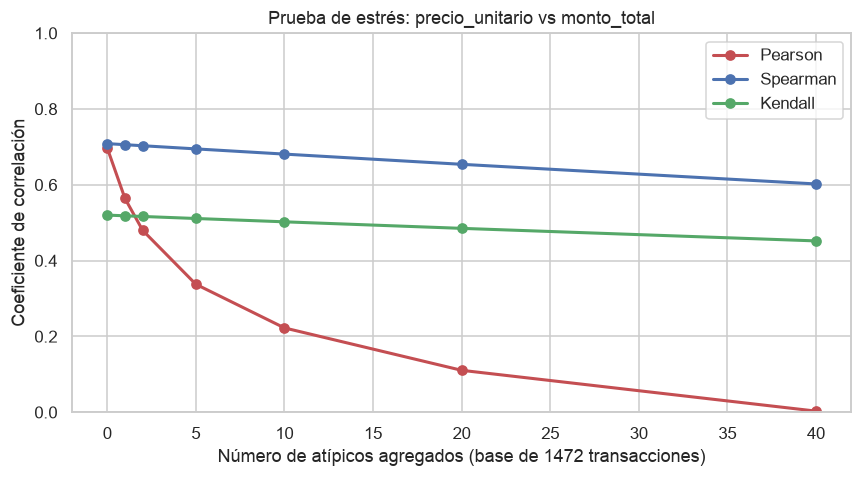

In [13]:
# (b) Prueba de estrés: se parte de datos limpios (sin extremos) y se agregan k atípicos
#     con precio bajo (percentil 10) pero un monto enorme (5 veces el máximo limpio).
limpio = df.loc[~mascara_ext, ["precio_unitario", "monto_total"]]
x0, y0 = limpio["precio_unitario"].to_numpy(), limpio["monto_total"].to_numpy()
x_atip = np.quantile(x0, 0.10)
y_atip = 5 * y0.max()

ks = [0, 1, 2, 5, 10, 20, 40]
resultados = []
for k in ks:
    x = np.concatenate([x0, np.full(k, x_atip)])
    y = np.concatenate([y0, np.full(k, y_atip)])
    c = tres_coeficientes(x, y)
    resultados.append({"atípicos agregados": k, "% de la muestra": 100 * k / len(x),
                       "Pearson": c["Pearson r"], "Spearman": c["Spearman ρ"], "Kendall": c["Kendall τ"]})
estres = pd.DataFrame(resultados).set_index("atípicos agregados")
display(estres.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for metodo in ["Pearson", "Spearman", "Kendall"]:
    ax.plot(estres.index, estres[metodo], marker="o", lw=2, color=COLOR[metodo], label=metodo)
ax.set_xlabel(f"Número de atípicos agregados (base de {len(limpio)} transacciones)")
ax.set_ylabel("Coeficiente de correlación")
ax.set_title("Prueba de estrés: precio_unitario vs monto_total")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Efecto de una relación monótona no lineal

Los coeficientes de rangos solo dependen del **orden** de los datos, así que no cambian si transformamos una variable con una función estrictamente creciente en el dominio observado (como raíz o cuadrado para valores no negativos). Pearson sí cambia, porque mide linealidad sobre los valores. Lo comprobamos con `antiguedad_cliente_meses` vs `puntos_fidelidad` (relación convexa).

In [14]:
x = df["antiguedad_cliente_meses"]
y = df["puntos_fidelidad"]
transformaciones = {
    "y original": y,
    "√y": np.sqrt(y),
    "log(y+1)": np.log1p(y),
    "y²": y ** 2,
}
filas = []
for nombre, yt in transformaciones.items():
    c = tres_coeficientes(x, yt)
    filas.append({"transformación de y": nombre, "Pearson": c["Pearson r"], "Spearman": c["Spearman ρ"], "Kendall": c["Kendall τ"]})
invarianza = pd.DataFrame(filas).set_index("transformación de y")
invarianza

,Pearson,Spearman,Kendall
transformación de y,,,
y original,0.961,0.99,0.917
√y,0.981,0.99,0.917
log(y+1),0.870,0.99,0.917
y²,0.744,0.99,0.917


### 3.4 Interpretación de los resultados

**Escala orientativa para leer la magnitud** (convención usada en la práctica, no una regla estricta): $|\text{coef}| < 0{,}1$ despreciable · $0{,}1$–$0{,}3$ débil · $0{,}3$–$0{,}5$ moderada · $0{,}5$–$0{,}7$ fuerte · $> 0{,}7$ muy fuerte. Kendall suele dar valores numéricamente menores que Spearman para la misma relación, así que no se compara contra esa escala de forma directa.

**Hallazgos principales**

1. **Atípicos: Los extremos reducen la asociación lineal observada.** En `cantidad_items — monto_total`, Pearson da $r = 0{,}26$ (débil) mientras que Spearman da $\rho = 0{,}67$ y Kendall $\tau = 0{,}52$ (fuerte). Al quitar las 28 compras extremas, Pearson sube a $0{,}61$ y los coeficientes de rangos casi no se mueven (cambios de 0,01). Con `precio_unitario — monto_total` ocurre lo mismo ($0{,}34$ → $0{,}70$ en Pearson; Spearman $0{,}70$ → $0{,}71$). En el conjunto completo la asociación lineal es menor que la asociación observada en el orden de las transacciones.
2. **La prueba de estrés lo confirma.** Con solo 10 atípicos agregados (0,7 % de la muestra) Pearson cae de $0{,}70$ a $0{,}22$; con 40 (2,6 %) llega a $\approx 0{,}00$. En el mismo escenario Spearman baja de $0{,}71$ a $0{,}60$ y Kendall de $0{,}52$ a $0{,}45$: se degradan de forma gradual y siguen detectando la relación.
3. **Relación monótona no lineal.** En `antiguedad — puntos_fidelidad` los tres coeficientes son altos (Pearson $0{,}96$, Spearman $0{,}99$, Kendall $0{,}92$) porque la curva es suave. La diferencia está en la estabilidad: al transformar `puntos` con una función monótona, **Spearman y Kendall no cambian** ($0{,}99$ y $0{,}92$ en todas las filas), mientras que Pearson oscila entre $0{,}74$ ($y^2$) y $0{,}98$ ($\sqrt{y}$). Pearson responde al cambio de forma por la transformación. Los métodos de rangos reflejan que se conserva el orden.
4. **Variables ordinales.** En `descuento_pct — satisfaccion` los tres coeficientes coinciden en el orden de magnitud (Pearson $0{,}27$, Spearman $0{,}26$, Kendall $0{,}22$): los tres apuntan a una asociación positiva débil. Kendall tau-b ajusta la concordancia por los empates.
5. **Significancia no es importancia.** Con $n = 1\,500$ casi todos los *p-values* son minúsculos, incluso para `tickets_soporte — monto_total` ($\rho = 0{,}16$, correlación débil). Para decidir hay que mirar la **magnitud** del coeficiente. El p-valor de Pearson es paramétrico y requiere especial cautela en estas distribuciones.

**¿Qué significa un 0,85 en términos de negocio?** Imaginemos un coeficiente de 0,85 entre `antiguedad_cliente_meses` y `puntos_fidelidad`:

- **Pearson $r = 0{,}85$:** la relación lineal entre ambas es muy fuerte; $r^2 \approx 0{,}72$, es decir, ≈ 72 % de la variabilidad de los puntos *se asocia linealmente* con la antigüedad. No dice cuántos puntos gana un cliente por mes (eso es la pendiente) ni que la antigüedad *produzca* los puntos.
- **Spearman $\rho = 0{,}85$:** los clientes más antiguos tienden, de forma muy consistente, a ubicarse más arriba en el ranking de puntos. Puede orientar una segmentación. El solapamiento de grupos como el 20 % superior se mide por separado.
- **Kendall tau = 0,85:** sin empates, la proporción de pares concordantes sería (1 + 0,85) / 2 = 92,5 %. Con empates, tau-b ajusta el denominador y esa conversión directa deja de aplicar. [Definición de Kendall tau-b en SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kendalltau.html)

## 4. Una correlación fuerte no implica causalidad

Una correlación solo dice que dos variables **se mueven juntas**. Para afirmar que una *causa* a la otra hace falta además que (1) la causa preceda al efecto, (2) se descarten **variables confusoras** que expliquen ambas, y (3) idealmente exista evidencia experimental (por ejemplo, un test A/B).

En este dataset hay un caso construido a propósito: la **antigüedad del cliente** influye tanto en cuánto compra (`monto_total`) como en cuántos `tickets_soporte` genera, pero los tickets **no** influyen en el monto. Veamos si la correlación lo delata.

In [15]:
def spearman_parcial(datos, x, y, z):
    # Spearman parcial: correlación de rangos entre x e y tras quitar el efecto (lineal en rangos) de z
    r = datos[[x, y, z]].rank()
    def residuo(v):
        pendiente, ordenada = np.polyfit(r[z], r[v], 1)
        return r[v] - (pendiente * r[z] + ordenada)
    return np.corrcoef(residuo(x), residuo(y))[0, 1]

rho_xy, p_xy = stats.spearmanr(df["tickets_soporte"], df["monto_total"])
rho_xz, _ = stats.spearmanr(df["tickets_soporte"], df["antiguedad_cliente_meses"])
rho_yz, _ = stats.spearmanr(df["monto_total"], df["antiguedad_cliente_meses"])
rho_par = spearman_parcial(df, "tickets_soporte", "monto_total", "antiguedad_cliente_meses")

confusor = pd.DataFrame({
    "Spearman ρ": [rho_xy, rho_xz, rho_yz, rho_par],
    "p-value": [p_xy, np.nan, np.nan, np.nan],
}, index=[
    "tickets_soporte — monto_total (observada)",
    "tickets_soporte — antiguedad (confusor)",
    "monto_total — antiguedad (confusor)",
    "tickets_soporte — monto_total, controlando antiguedad",
])
confusor.style.format({"Spearman ρ": "{:.3f}", "p-value": "{:.2e}"}, na_rep="—")

,Spearman ρ,p-value
tickets_soporte — monto_total (observada),0.157,9.62e-10
tickets_soporte — antiguedad (confusor),0.575,—
monto_total — antiguedad (confusor),0.226,—
"tickets_soporte — monto_total, controlando antiguedad",0.034,—


### 4.1 Lectura para el negocio

- **La correlación observada existe y es "estadísticamente significativa":** `tickets_soporte — monto_total` tiene $\rho = 0{,}16$ ($p < 0{,}001$). Una lectura ingenua diría "los clientes que abren más tickets compran más" y podría llevar a decisiones absurdas (¿fomentar tickets?, ¿atribuir ventas al soporte?).
- **El confusor lo explica:** la antigüedad se correlaciona con los tickets ($\rho = 0{,}58$) y con el monto ($\rho = 0{,}23$). Los clientes antiguos acumulan más tickets *y* compran más, sin que lo uno cause lo otro.
- **Al ajustar por antigüedad**, la correlación en rangos cae de 0,157 a 0,034. Esta comparación es descriptiva. Podemos identificar a la antigüedad como confusor porque conocemos cómo se generaron los datos.

**Otros ejemplos del mismo dataset**

- `antiguedad — puntos_fidelidad` ($\rho = 0{,}99$): aquí la relación *sí* es funcional, pero porque los puntos se **calculan** a partir de la antigüedad (es una regla de negocio), no porque la correlación lo demuestre.
- `descuento_pct — satisfaccion` ($\rho = 0{,}26$): es plausible que descontar mejore la satisfacción, pero la correlación sola no descarta causalidad inversa ni otros factores (por ejemplo, que se ofrezcan más descuentos a segmentos ya más satisfechos). Para afirmarlo haría falta un **experimento (test A/B)** con descuentos asignados al azar.

**Regla práctica:** usar la correlación para *descubrir hipótesis* y *priorizar* qué investigar; para decidir una acción (cambiar precios, invertir en soporte) exigir además control de confusores o evidencia experimental.

## 5. Conclusiones

### 5.1 ¿Qué método es el más robusto para este dataset?

**Kendall tau-b fue el más estable en la prueba de estrés de este dataset.** Spearman también resistió la contaminación y es útil para comunicar la asociación monótona en términos de rankings.

| Método | Precio y monto sin extremos | Con 40 extremos agregados | Caída respecto a su valor inicial |
|---|---:|---:|---:|
| Pearson | 0,697 | 0,003 | 99,6 % |
| Spearman | 0,709 | 0,602 | 15,1 % |
| Kendall tau-b | 0,520 | 0,452 | 13,1 % |

La caída relativa compara cada coeficiente con su propio punto de partida. La conclusión se limita al escenario de contaminación simulado. Spearman y Kendall también conservaron sus valores al transformar los puntos de fidelidad con funciones crecientes. Kendall tau-b ajusta los empates de variables ordinales como satisfacción. Pearson sigue siendo informativo cuando interesa específicamente la asociación lineal.

### 5.2 Mensajes para el negocio

1. El **monto de compra** se asocia positivamente con el **precio unitario** y la **cantidad de ítems**. Con todos los datos, Spearman da 0,698 y 0,667, respectivamente. Pearson da 0,335 y 0,261, y sube a 0,697 y 0,614 al excluir los extremos.
2. Los **puntos de fidelidad** siguen casi perfectamente el orden de la **antigüedad** ($\rho = 0{,}99$), pero eso es consecuencia de cómo se calculan, no un hallazgo causal.
3. La asociación en rangos entre **tickets de soporte y monto** baja de 0,157 a 0,034 al ajustar por antigüedad. Este resultado descriptivo ayuda a evitar atribuir ventas al soporte a partir de la correlación observada.
4. El **descuento** se asocia débilmente con la **satisfacción** ($\rho = 0{,}26$): vale la pena una prueba controlada antes de usarlo como palanca.

### 5.3 Limitaciones

Los datos son simulados y las relaciones se diseñaron a propósito, así que los valores exactos no son extrapolables a un negocio real. Los coeficientes de correlación miden asociación *monótona o lineal*; relaciones no monótonas (por ejemplo, en forma de U) pueden dar coeficientes cercanos a 0 aunque exista dependencia fuerte, y conviene siempre acompañar el número con un gráfico de dispersión.

### 5.4 Cumplimiento de los requisitos del entregable

- [x] Notebook `.ipynb` ejecutable, con código y resultados visibles (secciones 1–4).
- [x] Pearson, Spearman y Kendall calculados explícitamente con `scipy.stats` para seis pares de variables (sección 3.1) y como matrices completas con `DataFrame.corr` (sección 3).
- [x] Análisis de supuestos: histogramas, Q-Q plots, tests de Shapiro-Wilk y D'Agostino, detección de atípicos (sección 2).
- [x] Visualizaciones: heatmaps de los tres métodos, scatter plots de pares clave y gráfico de la prueba de estrés.
- [x] Explicación de por qué correlación no implica causalidad en el contexto del negocio (sección 4) e interpretación cualitativa de los coeficientes (sección 3.4).
- [x] Conclusión sobre el método más robusto (sección 5.1).